# Hafta 11 – GPT-2'yi Hızlı Eğitilebilir Hâle Getirmek

Geçen hafta GPT-2 mimarisini kendimiz yazdık ve OpenAI ağırlıklarıyla Hugging Face ile aynı logits'i aldık. Bu hafta modeli **sıfırdan eğitmeye** hazırlıyoruz. Üç soru var:
1. **Doğru eğitim:** Veriyi nasıl besleriz, parametreleri nasıl paylaşırız, ağırlıkları nasıl başlatırız?
2. **Hızlı eğitim:** GPU'yu nasıl daha verimli kullanırız?
3. **Kararlı eğitim:** GPT-3'ün optimizer ayarlarını ve büyük batch'i küçük GPU'da nasıl kurarız?


> **Not:** Hafta 10 notebook'unu değiştirmedim. Oradaki model, HF ağırlıklarıyla eşdeğerlik testi için yazılmıştı. Bu haftaki değişiklikler (flash attention, weight tying, yeni init, vocab 50.304) o testi bozardı. Bu yüzden model sınıfı burada geliştirilmiş haliyle yeniden yazıldı.


## 0. Kurulum ve Donanım Kontrolü

### Neyi Yapıyoruz?
Kütüphaneleri yüklüyor, cihazı (CUDA / MPS / CPU) buluyor ve GPU'nun hangi hızlandırmaları desteklediğini kontrol ediyoruz.

### Neden Yapıyoruz?
2. görevde bazı adımlar donanıma bağlı:
* **TF32 ve bfloat16** için Ampere (compute capability ≥ 8.0) veya daha yeni bir GPU gerekir. RTX 30xx/40xx ve A100 destekler. Colab T4 (7.5) desteklemez.
* **torch.compile** CUDA'da Triton kullanır. Triton Windows'ta varsayılan olarak gelmez (`pip install triton-windows` gerekir).

Notebook bu bayrakları başta belirler ve desteklenmeyen adımları **otomatik atlayıp nedenini yazar.**

In [1]:
%pip install -q tiktoken

In [2]:
# %pip install tiktoken matplotlib pandas
import math, time, inspect, os, dataclasses, contextlib, urllib.request
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
import tiktoken

device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
device_type = "cuda" if device.startswith("cuda") else device
print("PyTorch:", torch.__version__, "| cihaz:", device)

SUPPORTS_TF32 = SUPPORTS_BF16 = False
VRAM_GB = 0
if device == "cuda":
    props = torch.cuda.get_device_properties(0)
    cap = torch.cuda.get_device_capability(0)
    VRAM_GB = props.total_memory / 1e9
    SUPPORTS_TF32 = cap[0] >= 8
    SUPPORTS_BF16 = cap[0] >= 8 and torch.cuda.is_bf16_supported()
    print(f"GPU: {props.name} | VRAM: {VRAM_GB:.1f} GB | compute capability: {cap}")

def compile_available():
    if device != "cuda":
        return False, "torch.compile bu notebookta yalnızca CUDA'da deneniyor"
    try:
        import triton
        return True, f"triton {triton.__version__} bulundu"
    except ImportError:
        return False, "triton yok (Windows'ta: pip install triton-windows)"

COMPILE_OK, COMPILE_MSG = compile_available()
print("TF32 destekli mi:", SUPPORTS_TF32)
print("bfloat16 destekli mi:", SUPPORTS_BF16)
print("torch.compile:", COMPILE_OK, "-", COMPILE_MSG)

PyTorch: 2.11.0+cu130 | cihaz: cuda
GPU: Tesla T4 | VRAM: 15.6 GB | compute capability: (7, 5)
TF32 destekli mi: False
bfloat16 destekli mi: False
torch.compile: True - triton 3.6.0 bulundu


In [3]:
# Veri: Tiny Shakespeare (geçen haftaki input.txt). Dosya yoksa indirir.
if not os.path.exists("input.txt"):
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    urllib.request.urlretrieve(url, "input.txt")

text = open("input.txt", encoding="utf-8").read()
enc = tiktoken.get_encoding("gpt2")
all_tokens = torch.tensor(enc.encode(text), dtype=torch.long)
print(f"{len(text):,} karakter -> {len(all_tokens):,} token (karakter/token = {len(text)/len(all_tokens):.2f})")

# Micro-batch boyutunu VRAM'e göre seç. Karpathy A100 (80 GB) üzerinde B=16, T=1024 ile başlıyor.
# 1. ve 2. görevde attention matrisi (B, n_head, T, T) belleğe yazılıyor, bu yüzden küçük GPU'da T'yi küçük tutuyoruz.
if device == "cuda":
    B, T = (16, 1024) if VRAM_GB > 30 else (4, 1024) if VRAM_GB > 14 else (4, 512)
else:
    B, T = 2, 256
print(f"Micro-batch: B={B}, T={T} -> adım başına {B*T:,} token")

1,115,394 karakter -> 338,025 token (karakter/token = 3.30)
Micro-batch: B=4, T=1024 -> adım başına 4,096 token


## Model: Geçen Haftanın GPT-2'si + Bu Haftanın Değişiklikleri

### Neyi Yapıyoruz?
Hafta 10'daki `GPT` sınıfını aldık ve deneylerde açıp kapatabileceğimiz üç bayrak ekledik:

| Bayrak | Ne yapar | Görev |
|---|---|---|
| `weight_tying` | `wte` ile `lm_head` aynı matrisi paylaşır | 1 |
| `residual_scale` | Residual'a yazan katmanların std'sini $1/\sqrt{2 \cdot n_{layer}}$ ile küçültür | 1 |
| `use_flash` | Attention'ı `F.scaled_dot_product_attention` ile hesaplar | 2 |

Ayrıca `vocab_size` artık parametre (50.257 veya 50.304). Optimizer kurulumu (`configure_optimizers`) da modelin içinde, 3. görevde kullanacağız.

### Hafta 10'dan farkları
1. `__init__` sonunda `self.apply(self._init_weights)` var. PyTorch'un varsayılan başlatması yerine GPT-2'ninkini kullanıyoruz.
2. `c_proj` katmanlarına `NANOGPT_SCALE_INIT` işareti koyduk. Residual stream'e **doğrudan yazan** katmanlar bunlar (attention çıkışı ve MLP çıkışı).
3. `forward` her zaman tüm konumların logits'ini döndürüyor. Eğitimde zaten hepsine ihtiyaç var.

In [4]:
@dataclasses.dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257
    n_layer: int = 12
    n_head: int = 12
    n_embd: int = 768
    use_flash: bool = False       # Görev 2: flash attention
    weight_tying: bool = True     # Görev 1: wte <-> lm_head paylaşımı
    residual_scale: bool = True   # Görev 1: 1/sqrt(2*n_layer) ölçekleme


class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1      # residual stream'e yazan katman
        self.n_head, self.n_embd = config.n_head, config.n_embd
        self.use_flash = config.use_flash
        if not self.use_flash:
            self.register_buffer("bias", torch.tril(torch.ones(config.block_size, config.block_size))
                                 .view(1, 1, config.block_size, config.block_size), persistent=False)

    def forward(self, x):
        B, T, C = x.size()
        q, k, v = self.c_attn(x).split(self.n_embd, dim=2)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        if self.use_flash:
            # T x T attention matrisini belleğe hiç yazmadan hesaplar
            y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        else:
            att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(k.size(-1)))
            att = att.masked_fill(self.bias[:, :, :T, :T] == 0, float("-inf"))
            att = F.softmax(att, dim=-1)
            y = att @ v
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.c_proj(y)


class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu = nn.GELU(approximate="tanh")
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1      # residual stream'e yazan katman

    def forward(self, x):
        return self.c_proj(self.gelu(self.c_fc(x)))


class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))   # 1. ekleme
        x = x + self.mlp(self.ln_2(x))    # 2. ekleme  -> blok başına 2 ekleme
        return x


class GPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.transformer = nn.ModuleDict(dict(
            wte=nn.Embedding(config.vocab_size, config.n_embd),
            wpe=nn.Embedding(config.block_size, config.n_embd),
            h=nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f=nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)
        if config.weight_tying:
            self.transformer.wte.weight = self.lm_head.weight   # aynı tensör, iki yerde
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            std = 0.02
            if hasattr(module, "NANOGPT_SCALE_INIT") and self.config.residual_scale:
                std *= (2 * self.config.n_layer) ** -0.5
            torch.nn.init.normal_(module.weight, mean=0.0, std=std)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.size()
        assert T <= self.config.block_size
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)
        x = self.transformer.wte(idx) + self.transformer.wpe(pos)
        for block in self.transformer.h:
            x = block(x)
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    def configure_optimizers(self, weight_decay, learning_rate, device_type, verbose=True):
        params = {pn: p for pn, p in self.named_parameters() if p.requires_grad}
        decay = {pn: p for pn, p in params.items() if p.dim() >= 2}    # matmul ağırlıkları + embedding'ler
        nodecay = {pn: p for pn, p in params.items() if p.dim() < 2}   # bias'lar + LayerNorm parametreleri
        groups = [
            {"params": list(decay.values()), "weight_decay": weight_decay},
            {"params": list(nodecay.values()), "weight_decay": 0.0},
        ]
        stats = dict(
            n_decay_tensors=len(decay), n_decay_params=sum(p.numel() for p in decay.values()),
            n_nodecay_tensors=len(nodecay), n_nodecay_params=sum(p.numel() for p in nodecay.values()),
            nodecay_names=list(nodecay.keys()),
        )
        fused_available = "fused" in inspect.signature(torch.optim.AdamW).parameters
        use_fused = fused_available and device_type == "cuda"
        if verbose:
            print(f"weight decay UYGULANAN : {stats['n_decay_tensors']} tensör, {stats['n_decay_params']:,} parametre")
            print(f"weight decay UYGULANMAYAN: {stats['n_nodecay_tensors']} tensör, {stats['n_nodecay_params']:,} parametre")
            print(f"fused AdamW: {use_fused}")
        opt = torch.optim.AdamW(groups, lr=learning_rate, betas=(0.9, 0.95), eps=1e-8, fused=use_fused)
        return opt, stats


def count_params(model):
    # named_parameters paylaşılan tensörü bir kez sayar, weight tying'de doğru sonucu verir
    return sum(p.numel() for p in model.parameters())


# Hızlı sağlık kontrolü: rastgele başlatılmış modelin ilk loss'u ~ ln(vocab) olmalı
torch.manual_seed(1337)
_m = GPT(GPTConfig()).to(device)
_x = all_tokens[: B * T + 1].to(device)
with torch.no_grad():
    _, _loss = _m(_x[:-1].view(B, T), _x[1:].view(B, T))
print(f"Parametre sayısı: {count_params(_m):,}")
print(f"İlk loss: {_loss.item():.4f} | ln(50257) = {math.log(50257):.4f}")
del _m, _x, _loss
if device == "cuda": torch.cuda.empty_cache()

Parametre sayısı: 124,439,808
İlk loss: 10.9286 | ln(50257) = 10.8249


> **Geçen haftaya not:** İlk loss 10,93 çıktı, hafta 10'daki 10,87'den bile biraz yüksek. Yani std=0,02 başlatması ilk loss'u değiştirmedi. Sebep: PyTorch'un varsayılan Linear başlatmasının std'si $1/\sqrt{3 \cdot 768} \approx 0{,}0208$, yani 0,02 ile neredeyse aynı. Weight tying ile logit std'si $\approx 0{,}02 \cdot \sqrt{768} \approx 0{,}55$ oluyor. Bu da beklenen loss'u $\ln(50257) + \sigma^2/2 \approx 10{,}97$'ye çıkarıyor. Ölçtüğümüz 10,93 bununla tutarlı. Hafta 10'la aradaki farkın bir kısmı da batch boyutundan geliyor (128 token yerine 4.096 token).

---
# GÖREV 1 — Data Loader, Weight Tying ve Başlangıç Değerleri (1:02:00 – 1:22:18)

## 1.1 Data Loader

### Teori
Geçen hafta tek bir batch'i 200 kez gösterip ezberlettik. Gerçek eğitimde model her adımda **yeni** bir parça görmeli. Dil modelinde girdi ve hedef aynı metindir, hedef sadece **1 token kaydırılmıştır**:

```
token dizisi:  [t0 t1 t2 t3 t4 t5 t6 t7 t8]
x (girdi)   :  [t0 t1 t2 t3 t4 t5 t6 t7]
y (hedef)   :     [t1 t2 t3 t4 t5 t6 t7 t8]
```

### Mantık
* Her adımda metinden `B*T + 1` token kesiyoruz. `+1`, son konumun hedefi için.
* `x = buf[:-1]`, `y = buf[1:]`, ikisini `(B, T)` şekline getiriyoruz.
* İmleci `B*T` kadar ilerletiyoruz. Bir sonraki parça sığmıyorsa başa dönüyoruz. Bu bir **epoch**.

### Kod

In [5]:
class DataLoaderLite:
    def __init__(self, tokens, B, T, verbose=True):
        self.tokens, self.B, self.T = tokens, B, T
        self.current_position = 0
        if verbose:
            print(f"{len(tokens):,} token | 1 epoch = {len(tokens) // (B * T)} batch")

    def next_batch(self):
        B, T = self.B, self.T
        buf = self.tokens[self.current_position: self.current_position + B * T + 1]
        x = buf[:-1].view(B, T)
        y = buf[1:].view(B, T)
        self.current_position += B * T
        if self.current_position + B * T + 1 > len(self.tokens):   # sonraki batch sığmıyorsa başa dön
            self.current_position = 0
        return x, y


loader = DataLoaderLite(all_tokens, B, T)
x, y = loader.next_batch()
print("x şekli:", tuple(x.shape), "| y şekli:", tuple(y.shape))

# Kaydırmayı gözle görelim: ilk satırın ilk 10 konumu
print(f"\n{'konum':>5} | {'x (girdi)':<16} | {'y (hedef)':<16}")
for i in range(10):
    print(f"{i:>5} | {repr(enc.decode([x[0, i].item()])):<16} | {repr(enc.decode([y[0, i].item()])):<16}")

338,025 token | 1 epoch = 82 batch
x şekli: (4, 1024) | y şekli: (4, 1024)

konum | x (girdi)        | y (hedef)       
    0 | 'First'          | ' Citizen'      
    1 | ' Citizen'       | ':'             
    2 | ':'              | '\n'            
    3 | '\n'             | 'Before'        
    4 | 'Before'         | ' we'           
    5 | ' we'            | ' proceed'      
    6 | ' proceed'       | ' any'          
    7 | ' any'           | ' further'      
    8 | ' further'       | ','             
    9 | ','              | ' hear'         


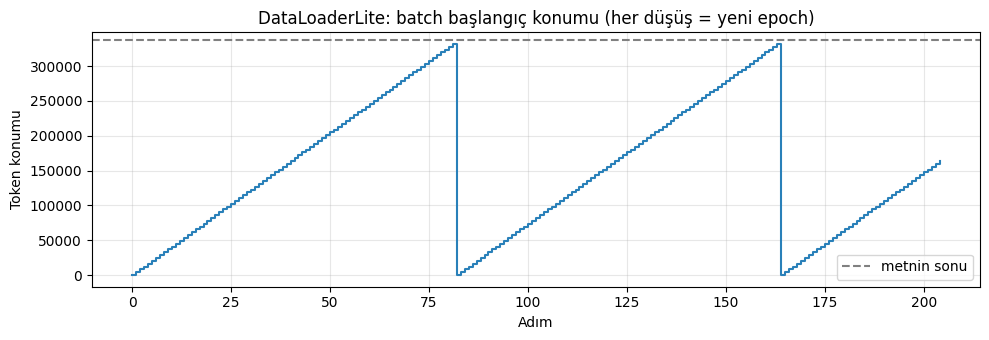

In [6]:
# Görsel: loader metin üzerinde nasıl ilerliyor? Testere dişi = epoch'lar.
viz_loader = DataLoaderLite(all_tokens, B, T, verbose=False)
n_batches = len(all_tokens) // (B * T)
positions = []
for _ in range(int(n_batches * 2.5)):
    positions.append(viz_loader.current_position)
    viz_loader.next_batch()

plt.figure(figsize=(10, 3.5))
plt.plot(positions, drawstyle="steps-post", color="#2980b9")
plt.axhline(len(all_tokens), color="gray", ls="--", label="metnin sonu")
plt.title("DataLoaderLite: batch başlangıç konumu (her düşüş = yeni epoch)")
plt.xlabel("Adım"); plt.ylabel("Token konumu"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 1.2 Weight Tying (Ağırlık Paylaşımı)

### Teori
GPT-2'de iki büyük matris aynı boyutta:
* `wte`: **(vocab, C)**, token id'sini vektöre çevirir (girdi tarafı).
* `lm_head`: **(vocab, C)**, vektörü her token için bir skora çevirir (çıktı tarafı).

GPT-2 (ve "Attention is All You Need") bu iki matrisi **aynı tensör** yapar (Press & Wolf, 2017).

### Mantık
* Anlamca benzer iki token girişte yakın embedding'lere sahip olmalı. Çıkışta da benzer bağlamlarda benzer skor almalı. İki matris aynı benzerlik yapısını öğreniyor, bu yüzden paylaşmak mantıklı bir varsayım (inductive bias).
* Paylaşılan matris **iki yerden gradyan alır**. Nadir token'ların embedding'i de çıkış katmanından sinyal alarak daha iyi öğrenilir.
* Parametre tasarrufu: $50.257 \times 768 = 38.597.376$. Bu, paylaşımlı 124M modelin **%31'i**, paylaşımsız 163M modelin **%23,7'si**. Karpathy'nin videoda söylediği "~%30" birinci oran.

### Kod
Aynı modeli paylaşımlı ve paylaşımsız kurup parametreleri sayıyoruz. Ardından OpenAI'ın GPT-2'sinde bu iki matrisin gerçekten aynı bellek adresinde olduğunu kontrol ediyoruz.

In [7]:
m_tied = GPT(GPTConfig(weight_tying=True))
m_untied = GPT(GPTConfig(weight_tying=False))
n_tied, n_untied = count_params(m_tied), count_params(m_untied)

print(f"Paylaşımlı    : {n_tied:,}")
print(f"Paylaşımsız   : {n_untied:,}")
print(f"Kazanç        : {n_untied - n_tied:,}  (= 50257 x 768 = {50257*768:,})")
print(f"Toplama oranı : %{100 * (n_untied - n_tied) / n_untied:.1f}")
print("Aynı tensör mü (data_ptr):", m_tied.transformer.wte.weight.data_ptr() == m_tied.lm_head.weight.data_ptr())

# OpenAI GPT-2'de de paylaşımlı mı? (transformers kuruluysa)
try:
    from transformers import GPT2LMHeadModel
    hf = GPT2LMHeadModel.from_pretrained("gpt2")
    sd = hf.state_dict()
    print("HF GPT-2 wte == lm_head (değer):", torch.equal(sd["transformer.wte.weight"], sd["lm_head.weight"]))
    print("HF GPT-2 aynı bellek adresi    :", sd["transformer.wte.weight"].data_ptr() == sd["lm_head.weight"].data_ptr())
    del hf, sd
except Exception as e:
    print("HF kontrolü atlandı:", e)

Paylaşımlı    : 124,439,808
Paylaşımsız   : 163,037,184
Kazanç        : 38,597,376  (= 50257 x 768 = 38,597,376)
Toplama oranı : %23.7
Aynı tensör mü (data_ptr): True


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

HF GPT-2 wte == lm_head (değer): True
HF GPT-2 aynı bellek adresi    : True


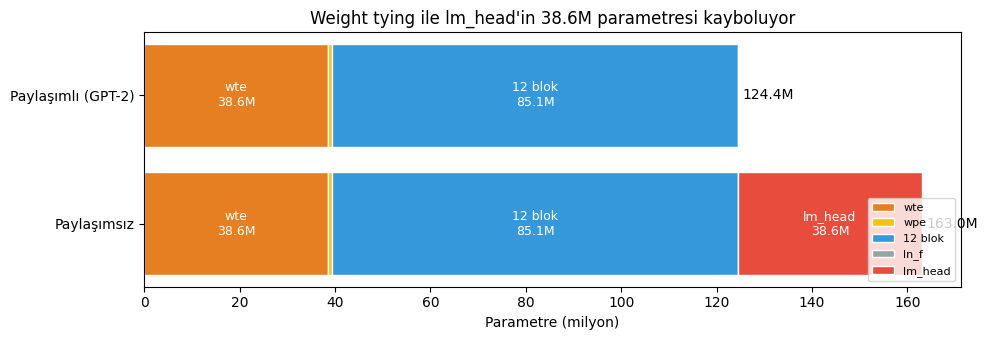

In [8]:
# Görsel: parametreler nereye gidiyor?
def param_breakdown(m):
    C, V = m.config.n_embd, m.config.vocab_size
    wte = V * C
    wpe = m.config.block_size * C
    blocks = sum(p.numel() for p in m.transformer.h.parameters())
    ln_f = sum(p.numel() for p in m.transformer.ln_f.parameters())
    lm_head = 0 if m.config.weight_tying else V * C
    return {"wte": wte, "wpe": wpe, "12 blok": blocks, "ln_f": ln_f, "lm_head": lm_head}

bd = {"Paylaşımsız": param_breakdown(m_untied), "Paylaşımlı (GPT-2)": param_breakdown(m_tied)}
colors = {"wte": "#e67e22", "wpe": "#f1c40f", "12 blok": "#3498db", "ln_f": "#95a5a6", "lm_head": "#e74c3c"}

fig, ax = plt.subplots(figsize=(10, 3.5))
for i, (name, parts) in enumerate(bd.items()):
    left = 0
    for k, v in parts.items():
        if v == 0: continue
        ax.barh(i, v / 1e6, left=left, color=colors[k], edgecolor="white", label=k if i == 0 else None)
        if v > 5e6:
            ax.text(left + v / 2e6, i, f"{k}\n{v/1e6:.1f}M", ha="center", va="center", fontsize=9, color="white")
        left += v / 1e6
    ax.text(left + 1, i, f"{left:.1f}M", va="center")
ax.set_yticks(range(len(bd))); ax.set_yticklabels(bd.keys())
ax.set_xlabel("Parametre (milyon)"); ax.set_title("Weight tying ile lm_head'in 38.6M parametresi kayboluyor")
ax.legend(loc="lower right", fontsize=8); plt.tight_layout(); plt.show()
del m_tied, m_untied

## 1.3 Başlangıç Değerleri: std 0.02 ve $1/\sqrt{2 \cdot n_{layer}}$

### Teori
**std = 0,02:** GPT-2 kodu Linear ve Embedding ağırlıklarını $\mathcal{N}(0, 0{,}02)$ ile başlatır, bias'ları sıfırlar. Xavier başlatma $1/\sqrt{d_{in}}$ der: $d=768$ için $\approx 0{,}036$, $d=1600$ (GPT-2 XL) için $\approx 0{,}025$. Yani 0,02 aynı mertebede, makul bir sabit.

**Residual stream sorunu:** Her blok residual stream'e iki kez **ekleme** yapar:
$$x \leftarrow x + \text{attn}(\text{ln}_1(x)), \qquad x \leftarrow x + \text{mlp}(\text{ln}_2(x))$$
Birbirinden bağımsız, varyansı $\sigma^2$ olan $N$ rastgele katkıyı toplarsak toplamın varyansı $N\sigma^2$, std'si $\sqrt{N}\,\sigma$ olur. 12 katmanlı modelde $N = 2 \times 12 = 24$ ekleme var. Hiçbir önlem almazsak residual stream derinleştikçe büyür.

### Mantık
Residual'a yazan katmanların (`c_proj`) ağırlıklarını $1/\sqrt{N}$ ile küçültürsek her katkının std'si $\sigma/\sqrt{N}$ olur. Toplamın std'si $\sqrt{N}\cdot\sigma/\sqrt{N} = \sigma$ olur. Yani residual stream'in sonundaki büyüklük, katman sayısı ne olursa olsun, **tek bir bloğun ölçeksiz katkısı mertebesinde** kalır. Stream yine katmandan katmana büyür, ama toplam büyüme $\sqrt{N}$ kat küçültülmüş olur. GPT-2 makalesindeki "$1/\sqrt{N}$ ile ölçekle" cümlesinin anlamı bu. $N$ katman değil, **ekleme** sayısı. Bu yüzden 2 ile çarpıyoruz.

> GPT-2 Pre-LN kullandığı için her bloğun girdisi LayerNorm'dan geçer. Bu yüzden bloğun katkısı residual'ın o anki büyüklüğünden bağımsızdır, ve embedding'in std'si (~0,03) blok katkılarının yanında çok küçük kalır. Ölçekli modelde de eğrinin yükselmesinin sebebi bu.

### Kod
Önce saf matematikle, sonra gerçek modelin içinde hook'larla gösteriyoruz.

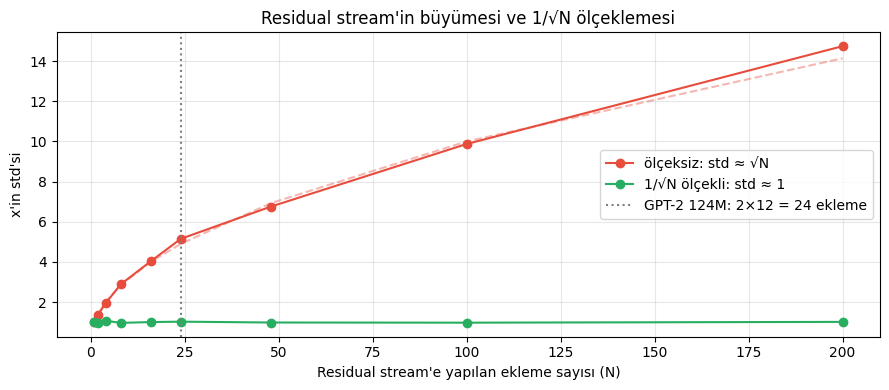

In [9]:
# (a) Saf deney: N tane bağımsız katkıyı topla, std nasıl büyüyor?
torch.manual_seed(0)
Ns = [1, 2, 4, 8, 16, 24, 48, 100, 200]
std_raw, std_scaled = [], []
for N in Ns:
    x_raw = torch.zeros(768); x_sc = torch.zeros(768)
    for _ in range(N):
        x_raw += torch.randn(768)
        x_sc += N ** -0.5 * torch.randn(768)
    std_raw.append(x_raw.std().item()); std_scaled.append(x_sc.std().item())

plt.figure(figsize=(9, 4))
plt.plot(Ns, std_raw, "o-", color="#e74c3c", label="ölçeksiz: std ≈ √N")
plt.plot(Ns, np.sqrt(Ns), "--", color="#e74c3c", alpha=0.4)
plt.plot(Ns, std_scaled, "o-", color="#27ae60", label="1/√N ölçekli: std ≈ 1")
plt.axvline(24, color="gray", ls=":", label="GPT-2 124M: 2×12 = 24 ekleme")
plt.xlabel("Residual stream'e yapılan ekleme sayısı (N)"); plt.ylabel("x'in std'si")
plt.title("Residual stream'in büyümesi ve 1/√N ölçeklemesi"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

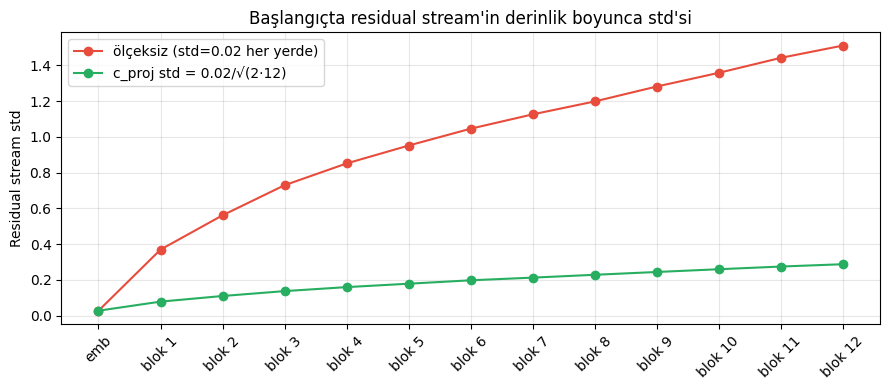

Son blok std | ölçeksiz: 1.5108 | ölçekli: 0.2882 | oran: 5.24x


In [10]:
# (b) Gerçek model: her bloğun çıkışında residual stream'in std'sini ölç (forward hook)
def residual_stds(residual_scale, seed=1337):
    torch.manual_seed(seed)
    m = GPT(GPTConfig(residual_scale=residual_scale)).to(device).eval()
    stds = []
    hooks = [blk.register_forward_hook(lambda mod, inp, out: stds.append(out.float().std().item()))
             for blk in m.transformer.h]
    xb, _ = DataLoaderLite(all_tokens, B, T, verbose=False).next_batch()
    with torch.no_grad():
        emb = m.transformer.wte(xb.to(device)) + m.transformer.wpe(torch.arange(T, device=device))
        m(xb.to(device))
    for h in hooks: h.remove()
    std0 = emb.std().item()
    del m
    return [std0] + stds

s_off, s_on = residual_stds(False), residual_stds(True)
layers = list(range(len(s_on)))
plt.figure(figsize=(9, 4))
plt.plot(layers, s_off, "o-", color="#e74c3c", label="ölçeksiz (std=0.02 her yerde)")
plt.plot(layers, s_on, "o-", color="#27ae60", label="c_proj std = 0.02/√(2·12)")
plt.xticks(layers, ["emb"] + [f"blok {i+1}" for i in range(len(s_on) - 1)], rotation=45)
plt.ylabel("Residual stream std"); plt.title("Başlangıçta residual stream'in derinlik boyunca std'si")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
print(f"Son blok std | ölçeksiz: {s_off[-1]:.4f} | ölçekli: {s_on[-1]:.4f} | oran: {s_off[-1]/s_on[-1]:.2f}x")
if device == "cuda": torch.cuda.empty_cache()

## 1.4 Metnin Tamamında Eğitim (Paylaşımlı vs Paylaşımsız)

### Neyi Yapıyoruz?
Data loader ile modeli tüm Tiny Shakespeare üzerinde birkaç düzine adım eğitiyoruz. Aynı deneyi weight tying açık ve kapalı yapıp loss eğrilerini üst üste çiziyoruz.

### Neden Yapıyoruz?
* Loss'un artık tek batch'i ezberleyerek değil, **yeni veriyi** görerek düşüp düşmediğini görmek.
* Weight tying'in 38,6M parametre eksiğine rağmen öğrenmeyi yavaşlatmadığını kontrol etmek.

> Henüz hızlandırma yok (fp32). Bu yüzden adım sayısı kısa tutuldu, `STEPS_1` ile artırabilirsin.

  [tied] adım   0 | loss 10.9286
  [tied] adım  10 | loss 7.3586
  [tied] adım  20 | loss 6.8719
  [tied] adım  30 | loss 6.4209
  [tied] adım  40 | loss 6.2730
  [tied] adım  49 | loss 6.0594
  [untied] adım   0 | loss 10.9809
  [untied] adım  10 | loss 7.4024
  [untied] adım  20 | loss 7.0544
  [untied] adım  30 | loss 6.5911
  [untied] adım  40 | loss 6.3838
  [untied] adım  49 | loss 6.1573


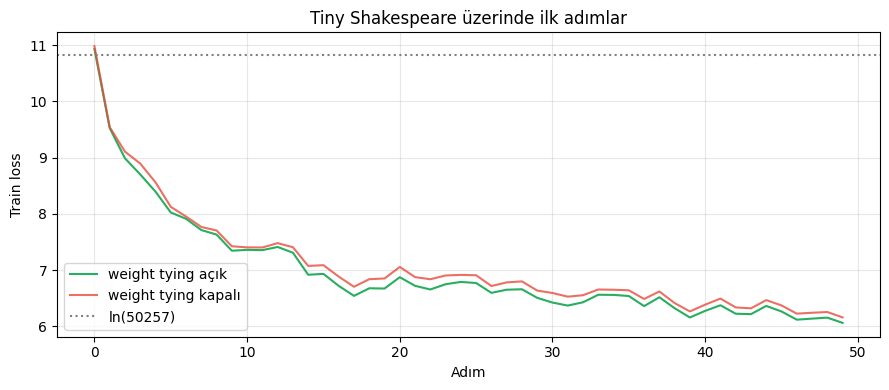

In [11]:
STEPS_1 = 50

def short_train(weight_tying, steps=STEPS_1, lr=3e-4):
    torch.manual_seed(1337)
    m = GPT(GPTConfig(weight_tying=weight_tying)).to(device)
    opt = torch.optim.AdamW(m.parameters(), lr=lr)
    ld = DataLoaderLite(all_tokens, B, T, verbose=False)
    losses = []
    for step in range(steps):
        xb, yb = ld.next_batch()
        opt.zero_grad()
        _, loss = m(xb.to(device), yb.to(device))
        loss.backward(); opt.step()
        losses.append(loss.item())
        if step % 10 == 0 or step == steps - 1:
            print(f"  [{'tied' if weight_tying else 'untied'}] adım {step:3d} | loss {loss.item():.4f}")
    del m, opt
    if device == "cuda": torch.cuda.empty_cache()
    return losses

loss_tied = short_train(True)
loss_untied = short_train(False)

plt.figure(figsize=(9, 4))
plt.plot(loss_tied, label="weight tying açık", color="#27ae60")
plt.plot(loss_untied, label="weight tying kapalı", color="#e74c3c", alpha=0.8)
plt.axhline(math.log(50257), color="gray", ls=":", label="ln(50257)")
plt.xlabel("Adım"); plt.ylabel("Train loss"); plt.title("Tiny Shakespeare üzerinde ilk adımlar")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### GÖREV 1 ANALİZİ VE DEĞERLENDİRME
* **Data loader:** Tiny Shakespeare 338.025 token. B=4, T=1024 ile 1 epoch 82 batch. `x` ile `y` arasında 1 token kayma olduğunu tabloda gördük ('First' → ' Citizen', ' Citizen' → ':').
* **Weight tying:** Paylaşımla parametre sayısı 163.037.184'ten 124.439.808'e indi. Kazanç 38.597.376 parametre (paylaşımlı modelin %31'i, paylaşımsız modelin %23,7'si). OpenAI'ın GPT-2'sinde de `wte` ve `lm_head` aynı tensör (hem değer hem bellek adresi kontrolü True). 50 adım sonunda paylaşımlı loss 6,06, paylaşımsız loss 6,16. 38,6M parametre daha azla biraz daha iyi sonuç aldık.
* **Başlangıç değerleri:** İlk loss 10,93, ln(50257)=10,82'ye yakın (aradaki ~0,1'lik fark logit std'sinden geliyor, yukarıdaki nota bak). Ölçeksiz modelde son bloğun residual std'si 1,51, ölçekli modelde 0,29. Oran 5,24x, teorik beklenti $\sqrt{24} \approx 4{,}9$. İki eğri de derinlikle artıyor. Ölçekleme büyümeyi tamamen durdurmuyor, toplam büyümeyi $\sqrt{24}$ kat küçültüyor.
* **Neden ölçekliyoruz? (kendi cümlelerimle):** Her transformer bloğu residual stream'e iki katkı ekliyor. Birbirinden bağımsız katkılar toplanınca varyanslar toplanır, std ekleme sayısının karekökü kadar büyür. 12 katmanda 24 ekleme var, önlem almazsak ağın sonlarına doğru aktivasyonlar ve logits büyür. Residual'a yazan `c_proj` ağırlıklarını $1/\sqrt{24}$ ile küçültünce her katkı küçülür, ağın sonundaki residual std'si katman sayısından bağımsız kalır. Böylece eğitim, büyük aktivasyonlarla değil dengeli bir noktadan başlar.

---
# GÖREV 2 — Eğitimi Hızlandırma (1:22:18 – 2:14:55)

## Teori: GPU zamanını nereye harcıyor?
Bir eğitim adımında GPU iki tür iş yapar:
1. **Hesap (compute):** Matris çarpımları. Tensor Core'lar bu işi düşük hassasiyette çok daha hızlı yapar.
2. **Bellek trafiği (memory):** Tensörleri GPU'nun ana belleğinden (HBM) çekip geri yazmak. GELU, softmax, LayerNorm gibi eleman bazlı işlemler hesap değil **bellek** bekler.

Dört adımın her biri bu iki darboğazdan birini hedefliyor:

| Adım | Hedef | Nasıl |
|---|---|---|
| **TF32** | Hesap | Matmul içinde mantisi 23 bitten 10 bite kırpar. Tensor Core'u kullanır, kodda değişiklik gerekmez. |
| **bfloat16 (autocast)** | Hesap + bellek | Aktivasyonları 16 bitte tutar. fp32 ile aynı **üs** aralığı olduğu için GradScaler gerekmez. |
| **float16** (T4) | Hesap + bellek | Üs aralığı dar (5 bit). Küçük gradyanlar sıfıra düşebilir, bu yüzden **GradScaler** ile loss büyütülür. |
| **torch.compile** | Bellek + Python yükü | Ardışık işlemleri tek kernel'da birleştirir (kernel fusion). Örneğin GELU'nun ara sonuçları belleğe yazılmaz. |
| **Flash attention** | Bellek | (T×T) attention matrisini hiç oluşturmaz. Online softmax ile parça parça hesaplar. Daha fazla FLOP, çok daha az bellek trafiği. |
| **vocab 50.304** | Hesap | 50.257 "çirkin" bir sayı. 50.304 = 2⁷·393, CUDA kernel'larının 64/128'lik bloklarına tam bölünür. Fazladan 47 token veride hiç geçmez, model onlara düşük olasılık vermeyi öğrenir. |

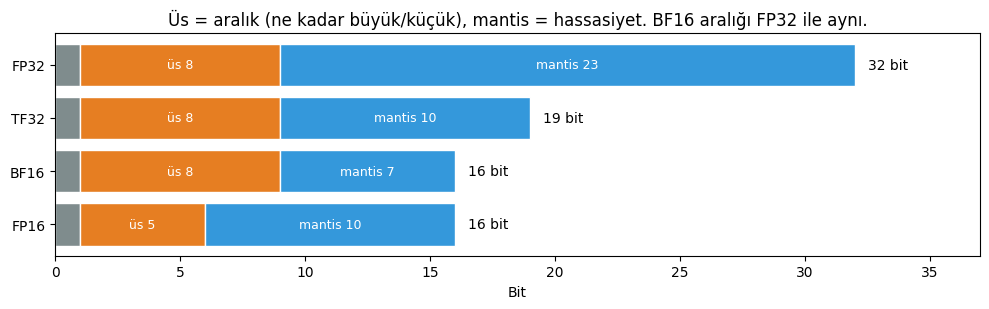

In [12]:
# Görsel 1: sayı formatlarının bit yapısı
formats = [("FP32", 1, 8, 23), ("TF32", 1, 8, 10), ("BF16", 1, 8, 7), ("FP16", 1, 5, 10)]
fig, ax = plt.subplots(figsize=(10, 3.2))
for i, (name, s, e, m) in enumerate(formats):
    ax.barh(i, s, color="#7f8c8d", edgecolor="white")
    ax.barh(i, e, left=s, color="#e67e22", edgecolor="white")
    ax.barh(i, m, left=s + e, color="#3498db", edgecolor="white")
    ax.text(s + e / 2, i, f"üs {e}", ha="center", va="center", color="white", fontsize=9)
    ax.text(s + e + m / 2, i, f"mantis {m}", ha="center", va="center", color="white", fontsize=9)
    ax.text(s + e + m + 0.5, i, f"{s+e+m} bit", va="center")
ax.set_yticks(range(len(formats))); ax.set_yticklabels([f[0] for f in formats]); ax.invert_yaxis()
ax.set_xlabel("Bit"); ax.set_xlim(0, 37)
ax.set_title("Üs = aralık (ne kadar büyük/küçük), mantis = hassasiyet. BF16 aralığı FP32 ile aynı.")
plt.tight_layout(); plt.show()

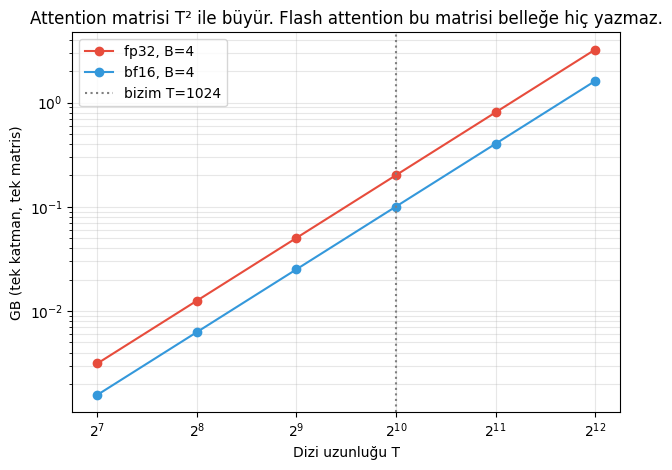

Not: backward için softmax öncesi/sonrası matrisler de saklanır, 12 katman boyunca toplam bunun birkaç katı.


In [13]:
# Görsel 2: manuel attention'da (B, n_head, T, T) matrisinin bir katmanda kapladığı bellek
Ts = np.array([128, 256, 512, 1024, 2048, 4096])
n_head = 12
for bytes_, label, c in [(4, "fp32", "#e74c3c"), (2, "bf16", "#3498db")]:
    gb = B * n_head * Ts**2 * bytes_ / 1e9
    plt.plot(Ts, gb, "o-", color=c, label=f"{label}, B={B}")
plt.axvline(T, color="gray", ls=":", label=f"bizim T={T}")
plt.yscale("log"); plt.xscale("log", base=2)
plt.xlabel("Dizi uzunluğu T"); plt.ylabel("GB (tek katman, tek matris)")
plt.title("Attention matrisi T² ile büyür. Flash attention bu matrisi belleğe hiç yazmaz.")
plt.legend(); plt.grid(alpha=0.3, which="both"); plt.tight_layout(); plt.show()
print("Not: backward için softmax öncesi/sonrası matrisler de saklanır, 12 katman boyunca toplam bunun birkaç katı.")


> **Windows notu:** PyTorch'un Windows paketlerinde flash-attention kernel'ı olmayabilir (`Torch was not compiled with flash attention` uyarısı). Bu durumda SDPA memory-efficient kernel'a düşer. Yine de T×T matrisi oluşmaz, bellek kazancı devam eder.

## Ölçüm Yöntemi
* GPU **asenkron** çalışır. `time.time()` sadece işi kuyruğa attığımız anı ölçer. Bu yüzden her adım sonunda `torch.cuda.synchronize()` ile GPU'nun bitirmesini bekliyoruz.
* İlk birkaç adım **ısınma** (warmup): torch.compile derleme yapar, CUDA kernel'ları seçilir. Bunları ortalamaya katmıyoruz.
* Adımlar **birikimli** ekleniyor (videodaki gibi): 1 → 1+2 → 1+2+3 ...

In [14]:
def set_tf32(enabled):
    if device == "cuda":
        torch.backends.cuda.matmul.allow_tf32 = enabled
        torch.backends.cudnn.allow_tf32 = enabled

def autocast_ctx(dtype):
    if dtype is None:
        return contextlib.nullcontext()
    return torch.autocast(device_type=device_type, dtype=dtype)

def make_scaler(dtype):
    # Sadece float16 için gerekli: küçük gradyanların sıfıra düşmesini önler
    return torch.amp.GradScaler("cuda") if (device_type == "cuda" and dtype == torch.float16) else None

def sync():
    if device == "cuda": torch.cuda.synchronize()
    elif device == "mps": torch.mps.synchronize()

def benchmark(tf32=False, dtype=None, compile_=False, flash=False, vocab=50257, warmup=5, steps=20):
    set_tf32(tf32)
    torch.manual_seed(1337)
    if device == "cuda":
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    model = GPT(GPTConfig(vocab_size=vocab, use_flash=flash)).to(device)
    if compile_:
        model = torch.compile(model)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4)
    scaler = make_scaler(dtype)
    ld = DataLoaderLite(all_tokens, B, T, verbose=False)
    times, losses = [], []
    for step in range(warmup + steps):
        xb, yb = ld.next_batch()
        xb, yb = xb.to(device), yb.to(device)
        t0 = time.perf_counter()
        opt.zero_grad(set_to_none=True)
        with autocast_ctx(dtype):
            _, loss = model(xb, yb)
        if scaler:
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        else:
            loss.backward(); opt.step()
        sync()
        dt = time.perf_counter() - t0
        if step >= warmup:
            times.append(dt); losses.append(loss.item())
    peak = torch.cuda.max_memory_allocated() / 1e9 if device == "cuda" else float("nan")
    del model, opt
    if device == "cuda": torch.cuda.empty_cache()
    ms = 1000 * np.mean(times)
    return dict(ms_per_step=ms, tok_per_s=B * T / np.mean(times), peak_mem_gb=peak, last_loss=losses[-1])

In [15]:
AMP_DTYPE = torch.bfloat16 if SUPPORTS_BF16 else (torch.float16 if device == "cuda" else None)
AMP_NAME = {torch.bfloat16: "bfloat16", torch.float16: "float16 + GradScaler", None: "-"}[AMP_DTYPE]

# Birikimli plan: her satır bir öncekinin üzerine bir adım ekler
plan = []
cfg = dict(tf32=False, dtype=None, compile_=False, flash=False, vocab=50257)
plan.append(("1) fp32 (baseline)", dict(cfg), None))

skip = None if SUPPORTS_TF32 else "GPU compute capability < 8.0, TF32 Tensor Core desteği yok"
if not skip: cfg["tf32"] = True
plan.append(("2) + TF32", dict(cfg), skip))

skip = None if AMP_DTYPE is not None else "bu cihazda autocast denenmiyor (CUDA değil)"
if not skip: cfg["dtype"] = AMP_DTYPE
plan.append((f"3) + {AMP_NAME}", dict(cfg), skip))

skip = None if COMPILE_OK else COMPILE_MSG
if not skip: cfg["compile_"] = True
plan.append(("4) + torch.compile", dict(cfg), skip))

cfg["flash"] = True
plan.append(("5) + flash attention", dict(cfg), None))

cfg["vocab"] = 50304
plan.append(("6) + vocab 50304", dict(cfg), None))

results = []
for name, c, skip_reason in plan:
    if skip_reason:
        print(f"ATLANDI  {name}: {skip_reason}")
        results.append(dict(adım=name, ms_per_step=np.nan, tok_per_s=np.nan, peak_mem_gb=np.nan, not_=skip_reason))
        continue
    print(f"ÖLÇÜLÜYOR {name} ...", end=" ", flush=True)
    try:
        r = benchmark(**c)
        print(f"{r['ms_per_step']:.1f} ms/adım | {r['tok_per_s']:,.0f} tok/s | tepe bellek {r['peak_mem_gb']:.2f} GB")
        results.append(dict(adım=name, **r, not_=""))
    except Exception as e:   # OOM, triton hatası vb.
        msg = f"{type(e).__name__}: {str(e)[:120]}"
        print("HATA ->", msg)
        results.append(dict(adım=name, ms_per_step=np.nan, tok_per_s=np.nan, peak_mem_gb=np.nan, not_=msg))
        if device == "cuda": torch.cuda.empty_cache()

set_tf32(SUPPORTS_TF32)   # sonraki hücreler için en hızlı ayara geri dön

ÖLÇÜLÜYOR 1) fp32 (baseline) ... 1285.7 ms/adım | 3,186 tok/s | tepe bellek 9.74 GB
ATLANDI  2) + TF32: GPU compute capability < 8.0, TF32 Tensor Core desteği yok
ÖLÇÜLÜYOR 3) + float16 + GradScaler ... 490.5 ms/adım | 8,351 tok/s | tepe bellek 9.31 GB
ÖLÇÜLÜYOR 4) + torch.compile ... 

W1101 12:45:22.077000 3297 torch/_inductor/utils.py:1731] [0/0] Not enough SMs to use max_autotune_gemm mode


337.6 ms/adım | 12,134 tok/s | tepe bellek 7.29 GB
ÖLÇÜLÜYOR 5) + flash attention ... 297.7 ms/adım | 13,759 tok/s | tepe bellek 4.83 GB
ÖLÇÜLÜYOR 6) + vocab 50304 ... 271.4 ms/adım | 15,091 tok/s | tepe bellek 4.48 GB


,adım,ms_per_step,tok_per_s,peak_mem_gb,hızlanma (x),önceki adıma göre (x),not
0,1) fp32 (baseline),1285.71,3185.80,9.74,1.00,NaN,
1,2) + TF32,NaN,NaN,NaN,NaN,NaN,"GPU compute capability < 8.0, TF32 Tensor Core..."
2,3) + float16 + GradScaler,490.46,8351.26,9.31,2.62,2.62,
3,4) + torch.compile,337.56,12134.28,7.29,3.81,1.45,
4,5) + flash attention,297.70,13758.98,4.83,4.32,1.13,
5,6) + vocab 50304,271.43,15090.59,4.48,4.74,1.10,


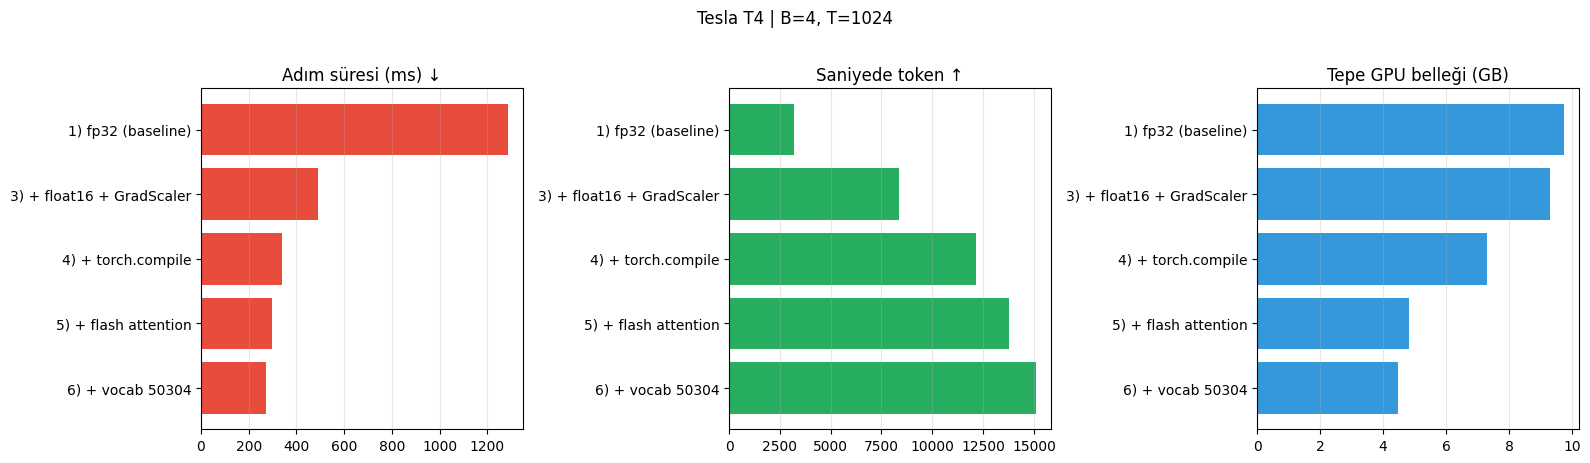

En çok kazandıran adım: 3) + float16 + GradScaler (2.62x)


In [16]:
df = pd.DataFrame(results).rename(columns={"not_": "not"})
base = df["ms_per_step"].iloc[0]
df["hızlanma (x)"] = base / df["ms_per_step"]
# Bir önceki ÖLÇÜLEN adıma göre kazanç
prev, gains = None, []
for ms in df["ms_per_step"]:
    gains.append(np.nan if (np.isnan(ms) or prev is None) else prev / ms)
    if not np.isnan(ms): prev = ms
df["önceki adıma göre (x)"] = gains
display(df[["adım", "ms_per_step", "tok_per_s", "peak_mem_gb", "hızlanma (x)", "önceki adıma göre (x)", "not"]].round(2))

ok = df.dropna(subset=["ms_per_step"])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].barh(ok["adım"], ok["ms_per_step"], color="#e74c3c"); axes[0].set_title("Adım süresi (ms) ↓"); axes[0].invert_yaxis()
axes[1].barh(ok["adım"], ok["tok_per_s"], color="#27ae60"); axes[1].set_title("Saniyede token ↑"); axes[1].invert_yaxis()
axes[2].barh(ok["adım"], ok["peak_mem_gb"], color="#3498db"); axes[2].set_title("Tepe GPU belleği (GB)"); axes[2].invert_yaxis()
for a in axes: a.grid(alpha=0.3, axis="x")
plt.suptitle(f"{torch.cuda.get_device_name(0) if device=='cuda' else device} | B={B}, T={T}", y=1.02)
plt.tight_layout(); plt.show()

best = df["önceki adıma göre (x)"].idxmax()
if not np.isnan(df["önceki adıma göre (x)"].max()):
    print(f"En çok kazandıran adım: {df.loc[best, 'adım']} ({df.loc[best, 'önceki adıma göre (x)']:.2f}x)")

### GÖREV 2 ANALİZİ VE DEĞERLENDİRME
**Donanım:** Tesla T4, 15,6 GB VRAM, compute capability (7, 5), B=4, T=1024 (adım başına 4.096 token)

| Adım | ms/adım | tok/s | Tepe bellek (GB) | Baseline'a göre | Önceki adıma göre |
|---|---|---|---|---|---|
| 1) fp32 | 1285,7 | 3.186 | 9,74 | 1,00x | – |
| 2) + TF32 | atlandı | – | – | – | – |
| 3) + float16 + GradScaler | 490,5 | 8.351 | 9,31 | 2,62x | 2,62x |
| 4) + torch.compile | 337,6 | 12.134 | 7,29 | 3,81x | 1,45x |
| 5) + flash attention | 297,7 | 13.759 | 4,83 | 4,32x | 1,13x |
| 6) + vocab 50.304 | 271,4 | 15.091 | 4,48 | 4,74x | 1,10x |

* **Atlanan adımlar ve nedenleri:** TF32 ve bfloat16. İkisi de compute capability 8.0 (Ampere) ve üstü istiyor, T4 ise 7.5 (Turing). bfloat16 yerine float16 + GradScaler kullandım. float16'nın üs aralığı dar (5 bit) olduğu için küçük gradyanlar sıfıra düşmesin diye GradScaler loss'u büyütüp sonra geri küçültüyor.
* **En çok kazandıran adım:** float16 (2,62x). T4'ün Tensor Core'ları sadece fp16 ile çalışıyor, fp32 matmul'lar normal CUDA çekirdeklerinde koşuyor. Yani videodaki TF32 sıçramasının T4'teki karşılığı bu adım. Teorik fark ~8x (fp16 ~65 TFLOPS, fp32 ~8 TFLOPS), ama işlemlerin hepsi matmul değil ve bir kısmı hesap yerine bellek beklediği için 2,6x'te kaldı.
* **Videoyla karşılaştırma:** Karpathy A100'de B=16 ile ~1000 ms'den ~93 ms'ye indi (~11x). En büyük sıçramalar TF32 (~3x) ve torch.compile (~2,3x) oldu. Bizde toplam 4,74x. Sıralama benzer: önce Tensor Core'u açan adım (onda TF32, bizde fp16), sonra compile. Flash attention ve vocab yuvarlama iki donanımda da daha küçük ama gerçek kazanç sağladı.
* **Bellek:** float16 belleği sadece 9,74 → 9,31 GB indirdi. Sebebi: autocast ağırlıkların fp32 kopyasını tutuyor, softmax ve cross-entropy de fp32'de hesaplanıyor. Asıl bellek kazancı torch.compile (7,29 GB, ara sonuçları belleğe yazmıyor) ve flash attention'dan (4,83 GB) geldi. Flash, T×T attention matrisini hiç oluşturmadığı için tepe belleği ~%34 düşürdü. Aynı GPU'ya artık B=8 sığabilir.
* **vocab 50.304:** 47 fazla token için daha fazla hesap yapmamıza rağmen adım %10 hızlandı. 50.304 = 2⁷·393, CUDA kernel'larının 64/128'lik bloklarına tam bölünüyor. 50.257'de ise kenarda kalan parça için ayrı, verimsiz bir kernel çalışıyor.
* **Not:** torch.compile sırasında çıkan `Not enough SMs to use max_autotune_gemm mode` uyarısı zararsız. T4'ün SM sayısı en agresif autotune modu için az, compile normal modda çalışmaya devam ediyor.

---
# GÖREV 3 — GPT-3'ün Eğitim Ayarları (2:14:55 – 2:46:52)

GPT-2 makalesi eğitim ayrıntılarını vermiyor. Karpathy bu yüzden mimarisi çok benzer olan **GPT-3 makalesinin Ek B'sindeki** ayarları kullanıyor. GPT-3 Small (125M) satırı:

| Ayar | Değer |
|---|---|
| Optimizer | AdamW, β₁=0,9, β₂=0,95, ε=1e-8 |
| Gradient clipping | global norm 1,0 |
| Learning rate | max 6e-4, warmup 375M token, cosine ile max'ın %10'una iner |
| Weight decay | 0,1 |
| Batch boyutu | 0,5M token (2¹⁹ = 524.288) |

## 3.1 AdamW Ayarları

### Teori
Adam her parametre için iki hareketli ortalama tutar: gradyanın ortalaması ($m$, β₁) ve karesinin ortalaması ($v$, β₂). Güncelleme yaklaşık $m / \sqrt{v}$ olur.

### Mantık
* β₂'nin varsayılanı 0,999. Bu yaklaşık son 1000 adımın ortalaması demek. **0,95** ise yaklaşık son 20 adım. Büyük dil modellerinde gradyan ölçeği hızlı değişir. $v$ daha çabuk uyum sağlarsa bir anda büyüyen gradyan, eski küçük $v$ ile bölünüp aşırı bir adıma dönüşmez. Sonuç: daha kararlı eğitim.
* **fused AdamW:** Tüm parametreleri tek CUDA kernel'ında günceller. Her parametre tensörü için ayrı kernel çağırmaz, bu yüzden daha hızlı.

## 3.2 Gradient Clipping

### Teori
Bütün parametrelerin gradyanlarını tek bir uzun vektör gibi düşünüp normunu alıyoruz:
$$\|g\| = \sqrt{\textstyle\sum_i g_i^2}$$
$\|g\| > 1$ ise tüm gradyanları $1/\|g\|$ ile çarpıp normu 1'e indiriyoruz. Yön aynı kalıyor, sadece boyut sınırlanıyor.

### Mantık
Kötü bir batch çok büyük bir gradyan üretebilir ve modeli bir adımda bozabilir ("şok"). Clipping bunu engeller. Normu **her adımda yazdırmak** iyi bir sağlık göstergesi: norm aniden yükseliyorsa bir sorun var demektir.

In [17]:
# Gradient clipping'i elle doğrulayalım: clip_grad_norm_ global normu döndürür
torch.manual_seed(0)
net = nn.Sequential(nn.Linear(10, 50), nn.GELU(), nn.Linear(50, 1))
(net(torch.randn(32, 10)).pow(2).mean() * 100).backward()   # bilerek büyük gradyan

manual_norm = torch.sqrt(sum((p.grad ** 2).sum() for p in net.parameters())).item()
returned = torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0).item()
after = torch.sqrt(sum((p.grad ** 2).sum() for p in net.parameters())).item()
print(f"Elle hesaplanan norm      : {manual_norm:.4f}")
print(f"clip_grad_norm_ döndürdüğü: {returned:.4f}  (clip ÖNCESİ norm)")
print(f"Clip sonrası norm         : {after:.4f}")

Elle hesaplanan norm      : 30.0058
clip_grad_norm_ döndürdüğü: 30.0058  (clip ÖNCESİ norm)
Clip sonrası norm         : 1.0000


## 3.3 Learning Rate Schedule: Warmup + Cosine Decay

### Teori
* **Warmup:** İlk adımlarda LR sıfıra yakından max'a doğrusal çıkar. Başta ağırlıklar rastgele, gradyanlar büyük ve tutarsız. Adam'ın $v$ istatistikleri de henüz oturmamış. Büyük LR ile başlamak modeli kötü bir bölgeye fırlatabilir.
* **Cosine decay:** Sonra LR, kosinüs eğrisiyle min_lr'ye (max'ın %10'u) iner. Eğitimin sonunda küçük adımlar, minimumun etrafında zıplamak yerine ona yerleşmeyi sağlar.

### Mantık
$$\text{lr}(t) = \begin{cases} \text{max\_lr}\cdot\frac{t+1}{\text{warmup}} & t < \text{warmup} \\ \text{min\_lr} + \tfrac{1}{2}\left(1+\cos\left(\pi\cdot\frac{t-\text{warmup}}{\text{max\_steps}-\text{warmup}}\right)\right)(\text{max\_lr}-\text{min\_lr}) & \text{warmup} \le t \le \text{max\_steps} \\ \text{min\_lr} & t > \text{max\_steps}\end{cases}$$

Karpathy'nin gerçek ayarı: 10B token / 0,5M batch = **19.073 adım**, warmup 375M / 0,5M ≈ **715 adım**. Bizim kısa koşumda warmup'ı adımların %10'u yapıyoruz.

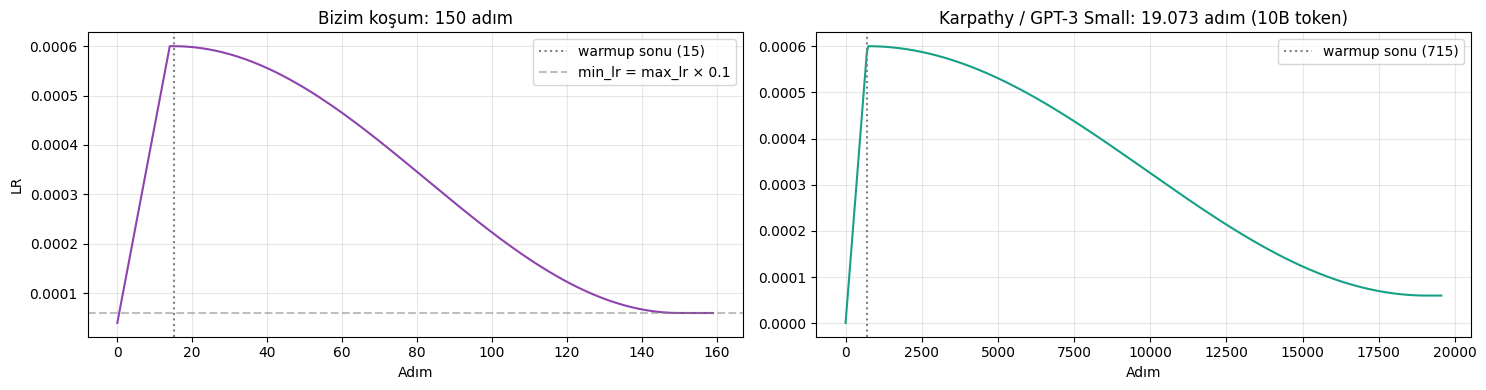

In [18]:
MAX_LR = 6e-4
MIN_LR = MAX_LR * 0.1
MAX_STEPS = 150                       # bizim kısa koşum
WARMUP_STEPS = max(1, MAX_STEPS // 10)

def get_lr(it, max_lr=MAX_LR, min_lr=MIN_LR, warmup=WARMUP_STEPS, max_steps=MAX_STEPS):
    if it < warmup:
        return max_lr * (it + 1) / warmup
    if it > max_steps:
        return min_lr
    ratio = (it - warmup) / (max_steps - warmup)
    coeff = 0.5 * (1.0 + math.cos(math.pi * ratio))   # 1 -> 0
    return min_lr + coeff * (max_lr - min_lr)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
steps = np.arange(MAX_STEPS + 10)
axes[0].plot(steps, [get_lr(s) for s in steps], color="#8e44ad")
axes[0].axvline(WARMUP_STEPS, color="gray", ls=":", label=f"warmup sonu ({WARMUP_STEPS})")
axes[0].axhline(MIN_LR, color="gray", ls="--", alpha=0.5, label="min_lr = max_lr × 0.1")
axes[0].set_title(f"Bizim koşum: {MAX_STEPS} adım"); axes[0].set_xlabel("Adım"); axes[0].set_ylabel("LR"); axes[0].legend()

big = np.arange(0, 19073 + 500, 50)
axes[1].plot(big, [get_lr(s, warmup=715, max_steps=19073) for s in big], color="#16a085")
axes[1].axvline(715, color="gray", ls=":", label="warmup sonu (715)")
axes[1].set_title("Karpathy / GPT-3 Small: 19.073 adım (10B token)"); axes[1].set_xlabel("Adım"); axes[1].legend()
for a in axes: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 3.4 Weight Decay (Sadece 2 Boyutlu Parametrelere)

### Teori
Weight decay her adımda ağırlıkları biraz sıfıra çeker ($w \leftarrow w - \text{lr}\cdot\lambda\cdot w$). Model, birkaç ağırlığı çok büyütmek yerine **çok sayıda ağırlığı az az kullanmaya** zorlanır. Bu bir regularization.

**AdamW** (Loshchilov & Hutter) bu çekme işlemini Adam'ın $m/\sqrt{v}$ ölçeklemesinden **ayırır** (decoupled). Klasik L2 cezasında, Adam büyük gradyanlı parametrelerde cezayı da zayıflatırdı.

### Mantık: Neden sadece 2D?
| Parametre | Boyut | Decay? | Neden |
|---|---|---|---|
| Linear ağırlıkları, `wte`, `wpe` | 2D | ✅ | Matris çarpımlarına giren asıl öğrenme kapasitesi |
| Bias'lar | 1D | ❌ | Sadece kaydırma yapar. Sıfıra çekmenin regularization faydası yok, ifade gücünü azaltır. |
| LayerNorm `weight` / `bias` | 1D | ❌ | Ölçek ve kaydırma. `weight`'i sıfıra çekmek normalizasyonu bozar. |

weight decay UYGULANAN : 50 tensör, 124,318,464 parametre
weight decay UYGULANMAYAN: 98 tensör, 121,344 parametre
fused AdamW: True

Decay uygulanmayan parametrelere örnek: ['transformer.h.0.ln_1.weight', 'transformer.h.0.ln_1.bias', 'transformer.h.0.attn.c_attn.bias', 'transformer.h.0.attn.c_proj.bias', 'transformer.h.0.ln_2.weight', 'transformer.h.0.ln_2.bias'] ...


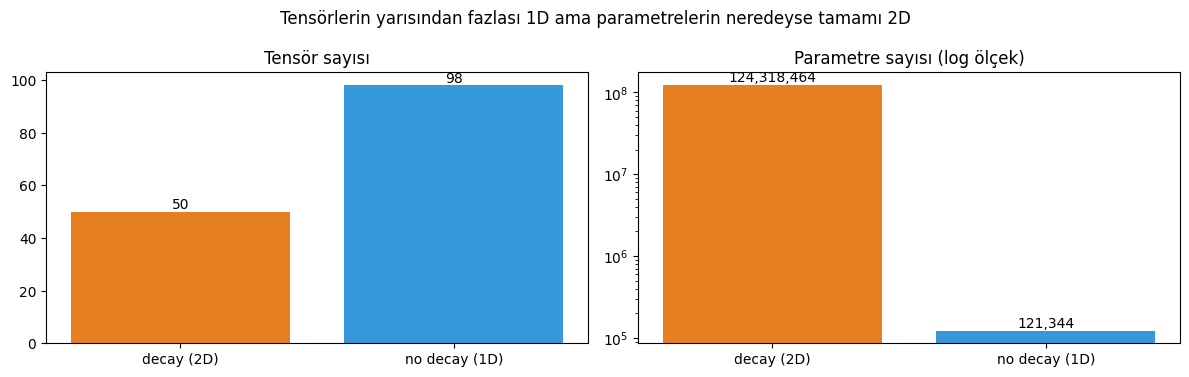

In [19]:
m_opt = GPT(GPTConfig())
_, st = m_opt.configure_optimizers(weight_decay=0.1, learning_rate=MAX_LR, device_type=device_type)
print("\nDecay uygulanmayan parametrelere örnek:", st["nodecay_names"][:6], "...")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(["decay (2D)", "no decay (1D)"], [st["n_decay_tensors"], st["n_nodecay_tensors"]], color=["#e67e22", "#3498db"])
axes[0].set_title("Tensör sayısı")
axes[1].bar(["decay (2D)", "no decay (1D)"], [st["n_decay_params"], st["n_nodecay_params"]], color=["#e67e22", "#3498db"])
axes[1].set_yscale("log"); axes[1].set_title("Parametre sayısı (log ölçek)")
for a, vals in zip(axes, [(st["n_decay_tensors"], st["n_nodecay_tensors"]), (st["n_decay_params"], st["n_nodecay_params"])]):
    for i, v in enumerate(vals): a.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.suptitle("Tensörlerin yarısından fazlası 1D ama parametrelerin neredeyse tamamı 2D"); plt.tight_layout(); plt.show()
del m_opt

## 3.5 Gradient Accumulation

### Teori
GPT-3 Small her adımda **~0,5M token** ile eğitiliyor. Bizim GPU'ya tek seferde $B \times T$ = birkaç bin token sığıyor. Çözüm: $K$ küçük batch'in (micro-batch) gradyanlarını **toplayıp** sonra tek bir optimizer adımı atmak.
$$K = \frac{\text{total\_batch\_size}}{B \times T}$$

### Mantık: Loss'u neden $K$'ya bölüyoruz?
`F.cross_entropy` varsayılan olarak **ortalama** alır. Büyük batch'in loss'u, tüm token'ların loss'larının ortalamasıdır:
$$L_{\text{büyük}} = \frac{1}{K}\sum_{k=1}^{K} L_k \quad\Rightarrow\quad \nabla L_{\text{büyük}} = \frac{1}{K}\sum_{k=1}^{K} \nabla L_k$$
PyTorch'ta `.backward()` gradyanı **toplar** (`+=`). $K$ kez `loss.backward()` çağırırsak $\sum \nabla L_k$ elde ederiz, yani doğru gradyanın **$K$ katını**. Bu, learning rate'i habersizce $K$ ile çarpmak gibidir. Her micro-batch'in loss'unu $K$'ya bölünce toplam tam olarak büyük batch'in ortalamasına eşit olur.

### Kod
Küçük bir ağda üç gradyanı karşılaştırıyoruz: (1) tek seferde büyük batch, (2) bölmeden biriktirme, (3) $K$'ya bölerek biriktirme.

Bölmeden biriktirme | max fark: 3.457163 | ortalama oran: 4.00 (beklenen 4)
K'ya bölerek        | max fark: 8.94e-08


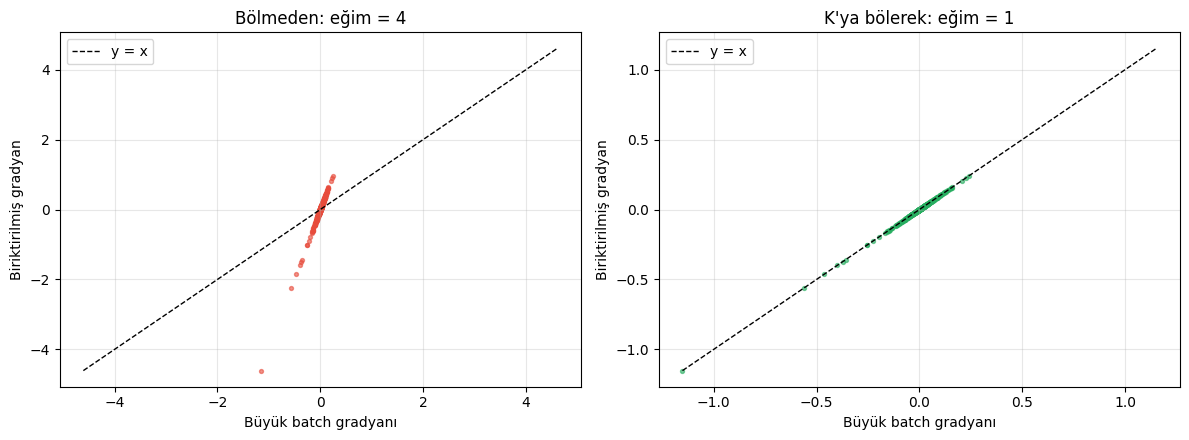

In [20]:
torch.manual_seed(42)
K = 4
net = nn.Sequential(nn.Linear(16, 32), nn.GELU(), nn.Linear(32, 1))
X, Y = torch.randn(K, 16), torch.randn(K, 1)
flat = lambda: torch.cat([p.grad.flatten() for p in net.parameters()]).clone()

net.zero_grad(); F.mse_loss(net(X), Y).backward(); g_full = flat()

net.zero_grad()
for i in range(K):
    F.mse_loss(net(X[i:i+1]), Y[i:i+1]).backward()          # bölmeden
g_nodiv = flat()

net.zero_grad()
for i in range(K):
    (F.mse_loss(net(X[i:i+1]), Y[i:i+1]) / K).backward()    # K'ya bölerek
g_div = flat()

print(f"Bölmeden biriktirme | max fark: {(g_full - g_nodiv).abs().max():.6f} | ortalama oran: {(g_nodiv / g_full).median():.2f} (beklenen {K})")
print(f"K'ya bölerek        | max fark: {(g_full - g_div).abs().max():.2e}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, g, title, c in [(axes[0], g_nodiv, f"Bölmeden: eğim = {K}", "#e74c3c"), (axes[1], g_div, "K'ya bölerek: eğim = 1", "#27ae60")]:
    ax.scatter(g_full, g, s=8, color=c, alpha=0.6)
    lim = max(g_full.abs().max(), g.abs().max()).item()
    ax.plot([-lim, lim], [-lim, lim], "k--", lw=1, label="y = x")
    ax.set_xlabel("Büyük batch gradyanı"); ax.set_ylabel("Biriktirilmiş gradyan"); ax.set_title(title); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 3.6 Hepsini Birleştirme: Eğitim Döngüsü

### Neyi Yapıyoruz?
Görev 2'de çalışan en hızlı ayarlarla, Görev 3'ün tüm parçalarını tek döngüde kullanıyoruz:
* `total_batch_size` token'lık büyük batch → `grad_accum_steps` micro-batch
* AdamW (β=0,9/0,95, ε=1e-8, weight decay 0,1 sadece 2D, fused)
* Gradient clipping 1,0, her adımda norm yazdırma
* Warmup + cosine LR

Metnin son %10'unu validation olarak ayırıyoruz. Tiny Shakespeare küçük, aynı veriyi defalarca göreceğiz. Overfit başladığında val loss'un train'den ayrıldığını görebilmek için.

> **Not:** Karpathy `total_batch_size = 2¹⁹` kullanıyor. Küçük GPU'da tek adım dakikalar sürer, bu yüzden 2¹⁵ ile başlıyoruz. Bir adım `grad_accum_steps` kat daha uzun sürer. İstersen değiştir.

In [21]:
# Görev 2'den gelen en hızlı ayarlar (çalışmayan bir adım varsa buradan kapat)
USE_TF32 = SUPPORTS_TF32
USE_COMPILE = COMPILE_OK
USE_FLASH = True
VOCAB = 50304

total_batch_size = 2 ** 15            # token / optimizer adımı (Karpathy: 2**19)
assert total_batch_size % (B * T) == 0, "total_batch_size, B*T'nin katı olmalı"
grad_accum_steps = total_batch_size // (B * T)

n_split = int(0.9 * len(all_tokens))
train_loader = DataLoaderLite(all_tokens[:n_split], B, T)
val_tokens = all_tokens[n_split:]
print(f"total_batch_size = {total_batch_size:,} | micro-batch = {B*T:,} | grad_accum_steps = {grad_accum_steps}")
print(f"1 epoch ≈ {n_split / total_batch_size:.1f} optimizer adımı -> {MAX_STEPS} adımda ≈ {MAX_STEPS * total_batch_size / n_split:.1f} epoch")

304,222 token | 1 epoch = 74 batch
total_batch_size = 32,768 | micro-batch = 4,096 | grad_accum_steps = 8
1 epoch ≈ 9.3 optimizer adımı -> 150 adımda ≈ 16.2 epoch


In [22]:
set_tf32(USE_TF32)
torch.manual_seed(1337)
if device == "cuda": torch.cuda.manual_seed(1337)

raw_model = GPT(GPTConfig(vocab_size=VOCAB, use_flash=USE_FLASH)).to(device)
optimizer, _ = raw_model.configure_optimizers(weight_decay=0.1, learning_rate=MAX_LR, device_type=device_type)
model = torch.compile(raw_model) if USE_COMPILE else raw_model
scaler = make_scaler(AMP_DTYPE)

@torch.no_grad()
def eval_val(n_batches=10):
    model.eval()
    ld = DataLoaderLite(val_tokens, B, T, verbose=False)
    total = 0.0
    for _ in range(n_batches):
        xb, yb = ld.next_batch()
        with autocast_ctx(AMP_DTYPE):
            _, l = model(xb.to(device), yb.to(device))
        total += l.item()
    model.train()
    return total / n_batches

log = {k: [] for k in ["step", "loss", "lr", "norm", "dt", "tok_s"]}
val_log = {"step": [], "loss": []}

for step in range(MAX_STEPS):
    t0 = time.perf_counter()
    last = step == MAX_STEPS - 1
    if step % 25 == 0 or last:
        vl = eval_val(); val_log["step"].append(step); val_log["loss"].append(vl)
        print(f"--- val loss: {vl:.4f}")

    optimizer.zero_grad(set_to_none=True)
    loss_accum = 0.0
    for micro_step in range(grad_accum_steps):
        xb, yb = train_loader.next_batch()
        xb, yb = xb.to(device), yb.to(device)
        with autocast_ctx(AMP_DTYPE):
            _, loss = model(xb, yb)
        loss = loss / grad_accum_steps          # ortalamayı korumak için
        loss_accum += loss.detach()
        (scaler.scale(loss) if scaler else loss).backward()

    if scaler: scaler.unscale_(optimizer)      # clip'ten önce gerçek gradyanlara dön
    norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    lr = get_lr(step)
    for g in optimizer.param_groups:
        g["lr"] = lr
    if scaler:
        scaler.step(optimizer); scaler.update()
    else:
        optimizer.step()
    sync()
    dt = time.perf_counter() - t0
    tok_s = total_batch_size / dt

    for k, v in zip(log, [step, loss_accum.item(), lr, norm.item(), dt * 1000, tok_s]):
        log[k].append(v)
    print(f"adım {step:4d} | loss {loss_accum.item():.4f} | lr {lr:.2e} | norm {norm.item():.4f} | dt {dt*1000:.0f} ms | {tok_s:,.0f} tok/s")

weight decay UYGULANAN : 50 tensör, 124,354,560 parametre
weight decay UYGULANMAYAN: 98 tensör, 121,344 parametre
fused AdamW: True
--- val loss: 10.9488
adım    0 | loss 10.9402 | lr 4.00e-05 | norm 29.8834 | dt 13636 ms | 2,403 tok/s
adım    1 | loss 9.7209 | lr 8.00e-05 | norm 10.8574 | dt 2023 ms | 16,199 tok/s
adım    2 | loss 9.2884 | lr 1.20e-04 | norm 8.0646 | dt 2032 ms | 16,128 tok/s
adım    3 | loss 9.8352 | lr 1.60e-04 | norm 8.5797 | dt 2066 ms | 15,860 tok/s
adım    4 | loss 9.2636 | lr 2.00e-04 | norm 4.6717 | dt 2064 ms | 15,873 tok/s
adım    5 | loss 8.8479 | lr 2.40e-04 | norm 3.4132 | dt 2083 ms | 15,732 tok/s
adım    6 | loss 8.6387 | lr 2.80e-04 | norm 2.7374 | dt 2092 ms | 15,662 tok/s
adım    7 | loss 8.4440 | lr 3.20e-04 | norm 1.7649 | dt 2087 ms | 15,699 tok/s
adım    8 | loss 8.2141 | lr 3.60e-04 | norm 2.5301 | dt 2064 ms | 15,872 tok/s
adım    9 | loss 7.9016 | lr 4.00e-04 | norm 2.5871 | dt 2043 ms | 16,038 tok/s
adım   10 | loss 7.5917 | lr 4.40e-04 | nor

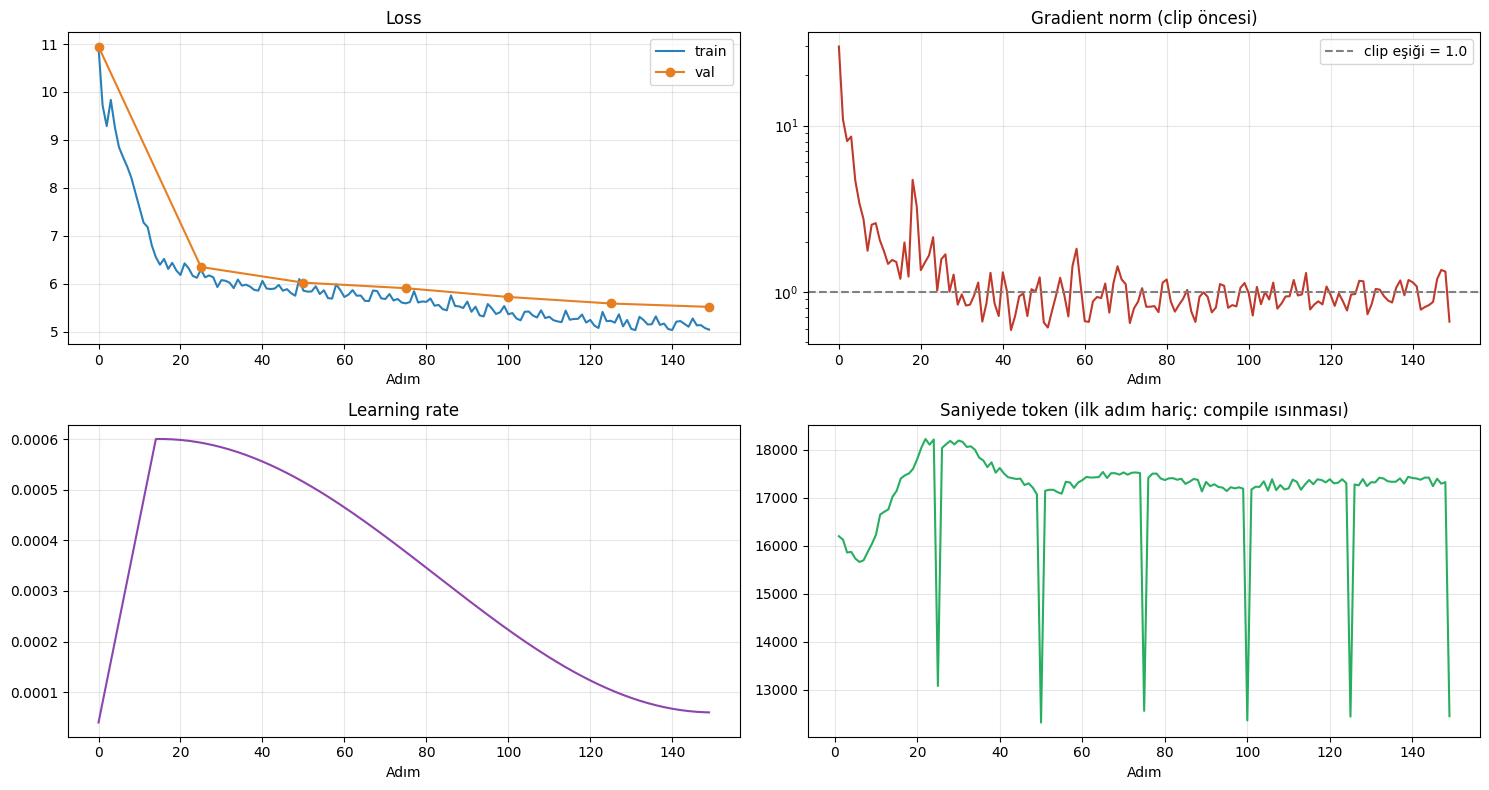

Normun 1.0'ı aştığı (clip uygulanan) adım sayısı: 70/150
Ortalama hız (ilk 3 adım hariç): 17,132 tok/s


In [23]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
axes[0, 0].plot(log["step"], log["loss"], label="train", color="#2980b9")
axes[0, 0].plot(val_log["step"], val_log["loss"], "o-", label="val", color="#e67e22")
axes[0, 0].set_title("Loss"); axes[0, 0].legend()
axes[0, 1].plot(log["step"], log["norm"], color="#c0392b")
axes[0, 1].axhline(1.0, color="gray", ls="--", label="clip eşiği = 1.0")
axes[0, 1].set_yscale("log"); axes[0, 1].set_title("Gradient norm (clip öncesi)"); axes[0, 1].legend()
axes[1, 0].plot(log["step"], log["lr"], color="#8e44ad"); axes[1, 0].set_title("Learning rate")
axes[1, 1].plot(log["step"][1:], log["tok_s"][1:], color="#27ae60")
axes[1, 1].set_title("Saniyede token (ilk adım hariç: compile ısınması)")
for a in axes.flat: a.set_xlabel("Adım"); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

clipped = sum(n > 1.0 for n in log["norm"])
print(f"Normun 1.0'ı aştığı (clip uygulanan) adım sayısı: {clipped}/{len(log['norm'])}")
print(f"Ortalama hız (ilk 3 adım hariç): {np.mean(log['tok_s'][3:]):,.0f} tok/s")

In [24]:
# Bonus: model Shakespeare gibi konuşmaya başladı mı?
@torch.no_grad()
def generate(prompt, max_new_tokens=60, top_k=50, seed=42):
    raw_model.eval()
    g = torch.Generator(device=device).manual_seed(seed)
    x = torch.tensor(enc.encode(prompt), device=device).unsqueeze(0)
    for _ in range(max_new_tokens):
        with autocast_ctx(AMP_DTYPE):
            logits, _ = raw_model(x[:, -raw_model.config.block_size:])
        logits = logits[:, -1, :].float()
        logits[:, enc.n_vocab:] = -float("inf")      # 50257..50303 dolgu token'larını asla seçme
        v, _ = torch.topk(logits, top_k)
        logits[logits < v[:, [-1]]] = -float("inf")
        nxt = torch.multinomial(F.softmax(logits, dim=-1), 1, generator=g)
        x = torch.cat([x, nxt], dim=1)
    raw_model.train()
    return enc.decode(x[0].tolist())

print(generate("ROMEO:"))

ROMEO: for you be that the
L, and a d blood in,
But she not,--
To do you all her will,
IUS: what not thou shall
And see it to your time from him and heUS:
Oy, no was my son,
How


### GÖREV 3 ANALİZİ VE DEĞERLENDİRME
* **AdamW:** β₁=0,9, β₂=0,95, ε=1e-8, fused=True. β₂=0,95 ikinci moment tahmininin son ~20 adımı yansıtmasını sağlıyor. Gradyan ölçeği değişince güncelleme boyutu daha çabuk uyum sağlıyor.
* **Gradient clipping:** Norm ilk adımda 29,9 idi, warmup sırasında hızla düştü (adım 10'da 2,0), adım ~30'dan sonra 0,6–1,4 arasında dolaştı. 150 adımın 70'inde clip devreye girdi. Adım 18–19'da 4,7'ye çıkan bir sıçrama var, LR'nin tepe noktasına (6e-4) yeni ulaştığı yer. Clipping tam bu tür şokların modeli bozmasını engellemek için var. Son adımlarda norm tekrar 1,3 civarına çıktı. Karpathy de LR düşerken normun hafifçe yükseldiğini videoda gösteriyor.
* **LR schedule:** 15 adım warmup (4e-5 → 6e-4), sonra 150. adıma kadar cosine ile 6,0e-5'e (max'ın %10'u) indi. Eğri yukarıda.
* **Weight decay:** 50 tensöre (124.354.560 parametre, vocab 50.304 ile) uygulandı, 98 tensöre (121.344 parametre) uygulanmadı. 50 = 12 blok × 4 Linear ağırlığı + `wte` + `wpe`. 98 = 12 blok × 8 (4 bias + 4 LayerNorm parametresi) + `ln_f`'nin 2'si. Bias ve LayerNorm parametreleri 1D. Bunlar ölçek/kaydırma yapar, sıfıra çekmek regularization sağlamaz, sadece modeli kısıtlar.
* **Gradient accumulation:** total_batch_size=32.768, micro-batch=4.096, grad_accum_steps=8. Küçük ağ deneyinde bölmeden biriktirilen gradyan büyük batch'in tam 4,00 katı çıktı, K'ya bölünce fark 8,9e-8 (float hassasiyeti).
* **Loss'u neden accumulation adım sayısına bölüyoruz (kendi cümlelerimle):** Cross-entropy batch'teki token'ların ortalamasını alıyor, ama `backward()` her çağrıda gradyanları üst üste topluyor. K micro-batch'i bölmeden biriktirirsem ortalamanın değil toplamın gradyanını, yani doğru gradyanın K katını elde ederim. Bu, learning rate'i farkında olmadan K ile çarpmak demek. Her micro-batch'in loss'unu K'ya bölünce toplanan gradyan, büyük batch'i tek seferde işleseydim alacağım gradyanla birebir aynı oluyor.
* **Eğitim:** 150 adımda train loss 10,94'ten ~5,04'e, val loss 10,95'ten 5,52'ye indi. Tiny Shakespeare'i ~16 epoch gördük ama val loss hiç yükselmedi, overfit henüz başlamadı. Model 150 adımda veriyi ezberleyecek kadar ilerleyemedi. Train ile val arasında ~0,4'lük bir fark var.
* **Hız:** Ortalama 17.132 tok/s. Bu, benchmark'taki 15.091'den yüksek, çünkü optimizer adımı 8 micro-batch'e bölünüyor ve fused AdamW kullanılıyor. Grafikte her 25 adımda bir görülen ~12.400'e düşüşler gerçek değil, o adımlarda val ölçümünün süresi adım süresine eklendiği için oluşuyor. İlk adımın 13,6 saniye sürmesi torch.compile derlemesinden.
* **Üretilen metin:** "ROMEO:" ile başlayan örnek, Shakespeare'in formatını (karakter adı + iki nokta + kısa satırlar) yakalamış ama cümleler anlamsız. 150 adım ve 4,9M token için beklenen bir sonuç.

---
# Haftanın Özeti

| Konu | Ne öğrendik |
|---|---|
| Data loader | Hedef = girdinin 1 token kaydırılmışı. Metni `B*T`'lik parçalarla dolaşıp başa dönüyoruz. |
| Weight tying | `wte` = `lm_head`. 38,6M parametre tasarrufu (paylaşımlı modelin %31'i), loss da biraz iyileşti (6,16 → 6,06). |
| Başlatma | std 0,02. Residual'a yazan katmanlar $1/\sqrt{2 n_{layer}}$ ile küçültülür, son residual std'si ~$\sqrt{24}$ kat küçülür (ölçtüğümüz 5,24x). |
| Hız | T4'te fp16 → compile → flash → vocab 50.304 ile toplam 4,74x. En büyük kazanç fp16'dan (2,62x), çünkü T4'te Tensor Core'u açan adım bu. Flash attention tepe belleği ~%34 düşürdü. |
| Optimizasyon | AdamW (0,9 / 0,95), clip 1,0, warmup + cosine, weight decay sadece 2D, gradient accumulation (loss / K). 150 adımda val loss 10,95 → 5,52. |

**Gelecek hafta:** Tiny Shakespeare yerine gerçek veri (FineWeb-Edu), validation ve HellaSwag ile ölçüm, kendi GPT-2'mizi eğitmek.